# A* no Lago Congelado

**DIM0126 - Inteligência Artificial para Jogos I**, Atividade 6 (Aula 27, pathfinding).

O notebook está dividido em três partes:

1. **Implementação do A\***: o A* da aula (Manhattan, custo 1) e a conferência contra o exemplo dos slides e o notebook base.
2. **Experimentos de cenário**: tamanho do grid, início, objetivo e buracos.
3. **Experimentos de custo**: terreno, segurança e tráfego, com o Uber como inspiração.

A busca fica no módulo [`astar.py`](./astar.py), para que todos os experimentos usem exatamente o mesmo A*. Ela recebe duas funções:

```python
custo_fn(origem, destino) -> float        # custo de um passo, entra em g(n)
heuristica_fn(celula, objetivo) -> float  # estimativa h(n)
```

In [1]:
import math
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import Image, display
from gymnasium.envs.toy_text.frozen_lake import generate_random_map

from astar import (Node, a_star, gerar_gif, custo_unitario, desenhar, euclidiana, executar_no_ambiente,
                   grid_com_caminho, heuristica_nula, manhattan, validar_caminho, NOMES_ACOES)

SEMENTE = 42
FIGURAS = Path("figuras")
FIGURAS.mkdir(exist_ok=True)

## Implementação do A*

### Estrutura do nó (slide 35)

Cada nó da árvore de busca guarda:

| Componente | Campo em `Node` |
|---|---|
| Estado | `estado`, a célula `(linha, coluna)` |
| Nó pai | `pai` |
| Ação | `acao` (0 = esquerda, 1 = baixo, 2 = direita, 3 = cima, a mesma numeração do Gymnasium) |
| Custo do caminho g(n) | `g` |

O A* tira da fronteira (abertos) o nó de menor $f(n) = g(n) + h(n)$. Os empates são desfeitos pelo menor $h$ e, depois, pela ordem de inserção. As células já expandidas vão para a lista de fechados. Buracos (`H`) não geram sucessores.

### Conferência com o exemplo da aula

Grid 4x4 padrão do `FrozenLake-v1`, com o agente em (0,0), o objetivo em (3,3), a distância Manhattan e custo 1 por passo. Nos slides 18 a 32 a busca termina com **g = 6**.

In [2]:
MAPA_AULA = ["SFFF", "FHFH", "FFFH", "HFFG"]

r = a_star(MAPA_AULA, (0, 0), (3, 3), custo_unitario, manhattan)
validar_caminho(MAPA_AULA, r)
assert r.custo == 6

print(grid_com_caminho(MAPA_AULA, r))
print()
print("caminho:   ", " -> ".join(map(str, r.caminho)))
print("ações:     ", ", ".join(NOMES_ACOES[a] for a in r.acoes))
print("fechados:  ", r.fechados)
print("h inicial: ", manhattan((0, 0), (3, 3)))
pd.DataFrame([r.metricas()])

SFFF
*HFH
**FH
H**G

caminho:    (0, 0) -> (1, 0) -> (2, 0) -> (2, 1) -> (3, 1) -> (3, 2) -> (3, 3)
ações:      baixo, baixo, direita, baixo, direita, direita
fechados:   [(0, 0), (1, 0), (2, 0), (2, 1), (3, 1), (3, 2)]
h inicial:  6.0


,encontrou,custo,passos,expandidos,gerados,max_fronteira,tempo_ms
0,True,6.0,6,6,9,3,0.072


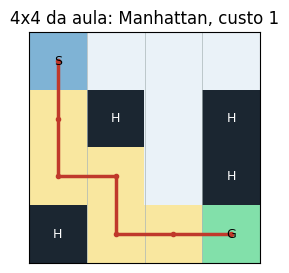

In [3]:
ax = desenhar(MAPA_AULA, r, titulo="4x4 da aula: Manhattan, custo 1")
plt.savefig(FIGURAS / "mapa_aula.png", dpi=150, bbox_inches="tight")
plt.show()

Em amarelo estão as células expandidas e em vermelho o caminho.

### Execução no Gymnasium

As ações do A* são executadas no `FrozenLake-v1` com `is_slippery=False`. O episódio precisa terminar no `G` com recompensa 1.

In [4]:
recompensa, terminou, estados = executar_no_ambiente(MAPA_AULA, r.acoes)
print(f"recompensa = {recompensa}, terminou = {terminou}, estados = {estados}")
assert terminou and recompensa == 1.0

recompensa = 1.0, terminou = True, estados = [0, 4, 8, 9, 13, 14, 15]


### Comparação com o notebook base da aula

O ponto de partida é o notebook do professor, [`Pratica_2_Completa.ipynb`](./Pratica_2_Completa.ipynb), que estava no Drive (slide 36). Ele roda o A* com Manhattan e custo 1 num mapa 8x8 próprio, com S em (0,7) e G em (7,7), e gera um GIF do agente andando. O `astar.py` mantém a mesma ideia e muda o seguinte:

| Notebook base | `astar.py` | Por quê |
|---|---|---|
| A heap guarda o caminho inteiro em cada entrada | Cada nó guarda `pai`, `acao` e `g` (slide 35), e o caminho é reconstruído no fim | Segue a estrutura de nó pedida e evita copiar listas a cada sucessor |
| `cost_function(acc_cost, a, b)` devolve o custo acumulado, e `custo_mov` é global | `custo_fn(origem, destino)` devolve só o custo do passo e é passada como parâmetro, como `heuristica_fn` | Os experimentos trocam o custo e a heurística sem editar a busca |
| O nó fechado nunca é reaberto, e todo vizinho é empilhado | Guarda o melhor g por célula, só empilha se o g melhorar e reabre um fechado se achar g menor | Com heurísticas que superestimam o custo, o caminho devolvido continua sendo o melhor encontrado |
| Empate em f desfeito pelo menor g | Empate desfeito pelo menor h e depois pela ordem de inserção | Tende a expandir menos nós, e a ordem fica determinística |
| Devolve só o caminho (ou `None`) | Devolve caminho, ações, custo, nós expandidos e gerados, tamanho máximo da fronteira, tempo e lista de fechados | Métricas necessárias para os experimentos e o relatório |
| GIF com `imageio` | `gerar_gif` com Pillow (já instalado junto com o matplotlib) | Uma dependência a menos |

No mapa do notebook base, as duas implementações encontram exatamente o mesmo caminho, com 25 passos.

In [5]:
MAPA_BASE = ["FFFFFFFS",
             "FHFHHHHH",
             "FHFFHFFF",
             "FHHFFFHF",
             "FHFHHHFF",
             "FHFFFHFH",
             "FHFHFHHH",
             "FFFHFFFG"]

CAMINHO_DO_NOTEBOOK_BASE = [(0, 7), (0, 6), (0, 5), (0, 4), (0, 3), (0, 2), (0, 1), (0, 0), (1, 0),
                            (2, 0), (3, 0), (4, 0), (5, 0), (6, 0), (7, 0), (7, 1), (7, 2), (6, 2),
                            (5, 2), (5, 3), (5, 4), (6, 4), (7, 4), (7, 5), (7, 6), (7, 7)]

r_base = a_star(MAPA_BASE)
validar_caminho(MAPA_BASE, r_base)
assert r_base.caminho == CAMINHO_DO_NOTEBOOK_BASE

print(grid_com_caminho(MAPA_BASE, r_base))
pd.DataFrame([r_base.metricas()])

*******S
*HFHHHHH
*HFFHFFF
*HHFFFHF
*HFHHHFF
*H***HFH
*H*H*HHH
***H***G


,encontrou,custo,passos,expandidos,gerados,max_fronteira,tempo_ms
0,True,25.0,25,38,40,2,0.228


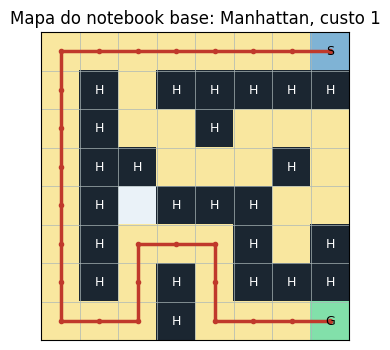

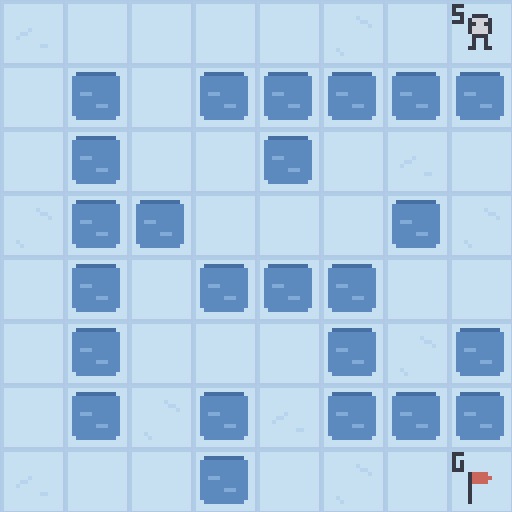

In [6]:
fig, ax = plt.subplots(figsize=(4, 4))
desenhar(MAPA_BASE, r_base, ax=ax, titulo="Mapa do notebook base: Manhattan, custo 1")
plt.savefig(FIGURAS / "mapa_base.png", dpi=150, bbox_inches="tight")
plt.show()

gerar_gif(MAPA_BASE, r_base.acoes, FIGURAS / "mapa_base.gif")
display(Image(filename=FIGURAS / "mapa_base.gif"))

Nesse mapa a Manhattan engana: o G fica logo abaixo do S, mas a fileira de buracos obriga o agente a dar a volta pela esquerda. Por isso o A* expande 38 nós para um caminho de 25 passos. Esse é um bom exemplo de mapa que engana a heurística.

### Verificação em mapas aleatórios

Para conferir a implementação fora do exemplo da aula, a busca roda em mapas aleatórios do Gymnasium (`p = 0.8`, 10 sementes por tamanho) com três heurísticas. Com uma heurística admissível, o custo precisa ser igual ao de $h = 0$ (Dijkstra), e o número de nós expandidos não pode ser maior.

Esta tabela só valida a implementação. A análise de tamanho de grid e de heurísticas fica nos experimentos de cenário.

In [7]:
linhas = []
for tamanho in (4, 8, 16, 32):
    for semente in range(10):
        mapa = generate_random_map(size=tamanho, p=0.8, seed=SEMENTE + semente)
        base = a_star(mapa, heuristica_fn=heuristica_nula)
        for nome, h in [("nula (Dijkstra)", heuristica_nula), ("manhattan", manhattan), ("euclidiana", euclidiana)]:
            res = a_star(mapa, heuristica_fn=h)
            validar_caminho(mapa, res)
            assert math.isclose(res.custo, base.custo)
            linhas.append({"tamanho": tamanho, "semente": semente, "heuristica": nome, **res.metricas()})
        rec, fim, _ = executar_no_ambiente(mapa, base.acoes)
        assert fim and rec == 1.0

df = pd.DataFrame(linhas)
df.groupby(["tamanho", "heuristica"])[["custo", "expandidos", "max_fronteira", "tempo_ms"]].mean().round(2)

custo  expandidos  max_fronteira  tempo_ms
tamanho heuristica                                                 
4       euclidiana         6.0         8.4            4.0      0.03
        manhattan          6.0         6.4            3.7      0.02
        nula (Dijkstra)    6.0        11.9            3.4      0.03
8       euclidiana        14.0        34.8           10.1      0.12
        manhattan         14.0        17.7           12.3      0.06
        nula (Dijkstra)   14.0        48.6            7.7      0.13
16      euclidiana        30.0       167.0           26.6      0.59
        manhattan         30.0        44.4           30.6      0.19
        nula (Dijkstra)   30.0       206.6           16.1      0.67
32      euclidiana        62.0       706.9           52.7      2.28
        manhattan         62.0       122.3           86.9      0.47
        nula (Dijkstra)   62.0       817.3           33.6      2.51

Os 40 mapas passam nas três verificações (caminho válido, custo igual ao de Dijkstra e recompensa 1 no Gymnasium), então a implementação está pronta para os experimentos.

---

## Experimentos de cenário

Na aula, o A* foi usado só no 4x4 padrão. Aqui o custo continua sendo **1 por passo**, e o que muda é o mapa:

1. **tamanho do grid**, de 4x4 a 64x64;
2. **posições do início e do objetivo** num mesmo mapa;
3. **buracos**: densidade aleatória e padrões montados à mão (parede, armadilha em "U", labirinto);
4. **mapas sem solução**;
5. **heurísticas**: além da Manhattan, $h = 0$ (Dijkstra), Euclidiana e Manhattan com peso $w > 1$, que deixa de ser admissível.

Os mapas são gerados pelo módulo [`cenarios.py`](./cenarios.py). Em todas as execuções, `rodar` valida o caminho, confere o custo contra Dijkstra e, quando a busca vai de S a G, executa as ações no `FrozenLake-v1` (o episódio precisa terminar no G com recompensa 1).

Métricas: **custo** do caminho, **nós expandidos** (retirados da fronteira), **tamanho máximo da fronteira** (memória) e tempo em ms. O tempo varia de uma execução para outra, então a comparação principal é pelo número de nós expandidos.

In [8]:
from astar import encontrar
from cenarios import (alcancaveis, existe_caminho, manhattan_ponderada, mapa_armadilha_u,
                      mapa_labirinto, mapa_objetivo_isolado, mapa_parede, montar_mapa,
                      posicionar, rodar)

HEURISTICAS = {
    "nula (Dijkstra)": heuristica_nula,
    "manhattan": manhattan,
    "euclidiana": euclidiana,
}
HEURISTICAS_PONDERADAS = {
    "manhattan ×1.5": manhattan_ponderada(1.5),
    "manhattan ×2": manhattan_ponderada(2),
    "manhattan ×5": manhattan_ponderada(5),
}

# Cor fixa por heurística, a mesma em todos os gráficos.
CORES = {
    "nula (Dijkstra)": "#2a78d6",
    "manhattan": "#eb6834",
    "euclidiana": "#1baf7a",
    "manhattan ×1.5": "#eda100",
    "manhattan ×2": "#e87ba4",
    "manhattan ×5": "#6250d6",
}

def estilo(ax, titulo, xlabel, ylabel):
    ax.set_title(titulo, loc="left", fontsize=11)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color("#8a8984")
    ax.tick_params(colors="#52514e")
    ax.grid(axis="y", color="#e4e3df", linewidth=0.8)
    ax.set_axisbelow(True)

def linhas_por_heuristica(ax, df, x, y, heuristicas):
    for nome in heuristicas:
        d = df[df.heuristica == nome]
        ax.plot(d[x], d[y], color=CORES[nome], linewidth=2, marker="o", markersize=6, label=nome)

### 1. Tamanho do grid

Para cada tamanho são usados 20 mapas do `generate_random_map` do Gymnasium, com `p = 0.8` (80% de gelo), S em (0,0) e G no canto oposto. O gerador do Gymnasium só devolve mapas que têm caminho.

In [9]:
TAMANHOS = [4, 8, 16, 32, 64]
N_MAPAS = 20

linhas = []
for tamanho in TAMANHOS:
    for k in range(N_MAPAS):
        mapa = generate_random_map(size=tamanho, p=0.8, seed=SEMENTE + k)
        livres = sum(l.count("F") for l in mapa) + 2
        for linha in rodar(mapa, HEURISTICAS):
            linhas.append({"tamanho": tamanho, "mapa": k, "livres": livres, **linha})

df_tam = pd.DataFrame(linhas)
df_tam["% livres expandidas"] = 100 * df_tam.expandidos / df_tam.livres
resumo_tam = (df_tam.groupby(["tamanho", "heuristica"], sort=False)
              [["custo", "expandidos", "% livres expandidas", "max_fronteira", "tempo_ms"]]
              .mean().round(1))
resumo_tam

custo  expandidos  % livres expandidas  \
tamanho heuristica                                                
4       nula (Dijkstra)    6.0        11.8                 90.3   
        manhattan          6.0         6.6                 51.2   
        euclidiana         6.0         8.2                 62.5   
8       nula (Dijkstra)   14.0        49.3                 94.6   
        manhattan         14.0        17.0                 32.7   
        euclidiana        14.0        35.2                 67.4   
16      nula (Dijkstra)   30.0       206.5                 98.9   
        manhattan         30.0        43.6                 20.9   
        euclidiana        30.0       165.2                 79.1   
32      nula (Dijkstra)   62.2       813.2                 99.3   
        manhattan         62.2       123.2                 15.0   
        euclidiana        62.2       695.6                 84.9   
64      nula (Dijkstra)  126.0      3265.4                 99.7   
        manhattan        126.0       366.2                 11.2   
        euclidiana       126.0      2939.3                 89.7   

                         max_fronteira  tempo_ms  
tamanho heuristica                                
4       nula (Dijkstra)            3.2       0.0  
        manhattan                  3.8       0.0  
        euclidiana                 4.0       0.0  
8       nula (Dijkstra)            7.7       0.1  
        manhattan                 12.0       0.1  
        euclidiana                10.2       0.1  
16      nula (Dijkstra)           16.2       0.6  
        manhattan                 32.2       0.2  
        euclidiana                25.6       0.5  
32      nula (Dijkstra)           33.0       2.5  
        manhattan                 85.8       0.6  
        euclidiana                51.4       2.5  
64      nula (Dijkstra)           63.8       9.5  
        manhattan                239.1       1.4  
        euclidiana               106.0       9.4

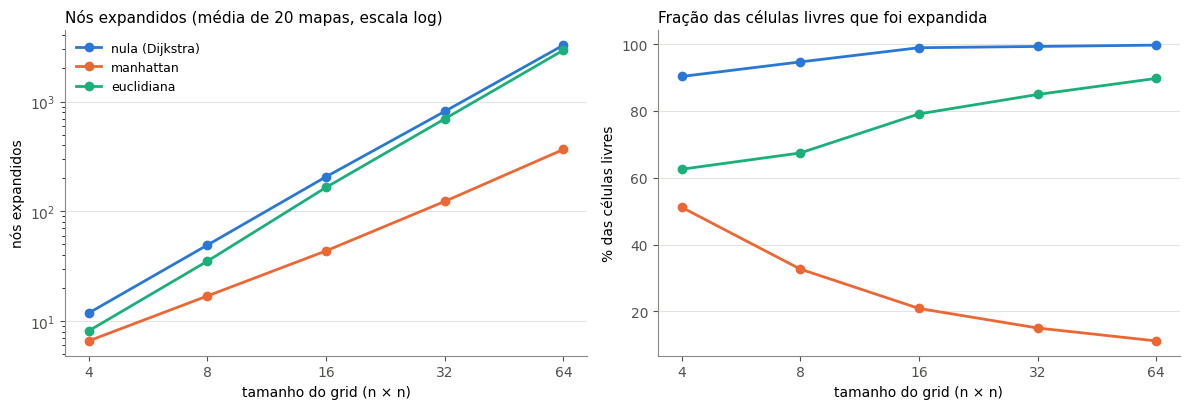

In [10]:
media_tam = df_tam.groupby(["heuristica", "tamanho"], sort=False).mean(numeric_only=True).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
linhas_por_heuristica(axes[0], media_tam, "tamanho", "expandidos", HEURISTICAS)
axes[0].set_yscale("log")
estilo(axes[0], "Nós expandidos (média de 20 mapas, escala log)", "tamanho do grid (n × n)", "nós expandidos")
linhas_por_heuristica(axes[1], media_tam, "tamanho", "% livres expandidas", HEURISTICAS)
estilo(axes[1], "Fração das células livres que foi expandida", "tamanho do grid (n × n)", "% das células livres")
for ax in axes:
    ax.set_xscale("log", base=2)
    ax.set_xticks(TAMANHOS, [str(t) for t in TAMANHOS])
axes[0].legend(frameon=False, fontsize=9, loc="upper left")
plt.tight_layout()
plt.savefig(FIGURAS / "cenario_tamanho.png", dpi=150, bbox_inches="tight")
plt.show()

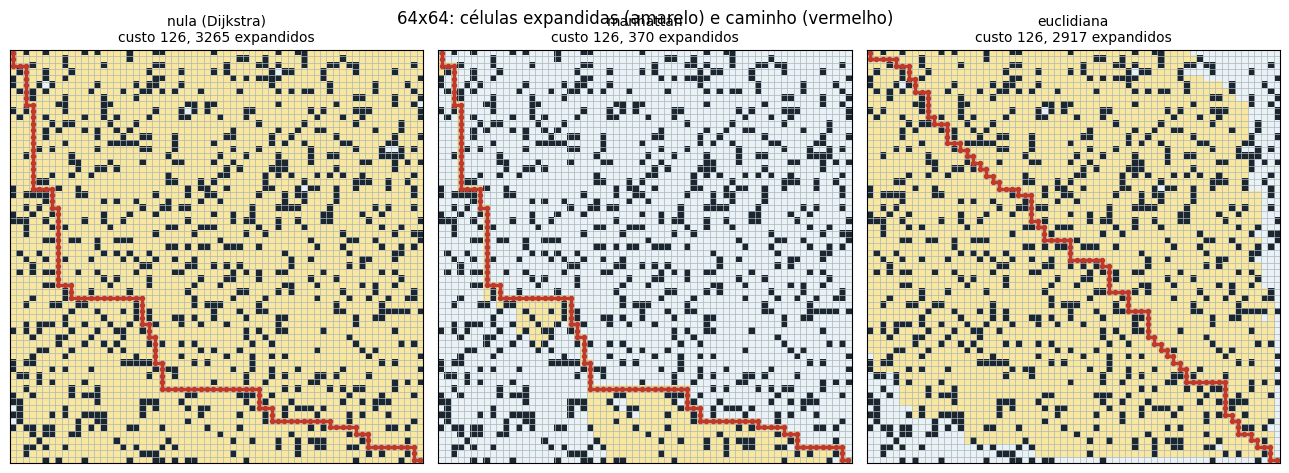

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.8))
mapa64 = generate_random_map(size=64, p=0.8, seed=SEMENTE)
for ax, (nome, h) in zip(axes, HEURISTICAS.items()):
    desenhar(mapa64, a_star(mapa64, heuristica_fn=h), ax=ax)
    ax.set_title(f"{nome}\n{ax.get_title()}", fontsize=10)
plt.suptitle("64x64: células expandidas (amarelo) e caminho (vermelho)")
plt.tight_layout()
plt.savefig(FIGURAS / "cenario_64x64.png", dpi=150, bbox_inches="tight")
plt.show()

### 2. Posições do início e do objetivo

O mesmo mapa 16x16 (mesmos buracos) é usado com S e G em lugares diferentes. A semente do mapa é escolhida para que todas as combinações tenham caminho.

A coluna `h(S) / custo` mede o quanto a Manhattan inicial acerta o custo real: 1 quer dizer que o caminho é tão curto quanto a distância em grade, sem desvios.

In [12]:
N = 16
POSICOES = {
    "cantos opostos":         ((0, 0), (15, 15)),
    "mesmo lado":             ((0, 0), (0, 15)),
    "centro → canto":         ((8, 8), (15, 15)),
    "canto → centro":         ((15, 15), (8, 8)),
    "vizinhos na diagonal":   ((7, 7), (8, 8)),
    "objetivo entre buracos": None,  # escolhido abaixo
}

def mais_cercada(mapa, inicio):
    # Célula alcançável com mais buracos em volta (desempate: a mais distante do início).
    candidatas = []
    for i in range(len(mapa)):
        for j in range(len(mapa)):
            if mapa[i][j] == "H" or (i, j) == inicio:
                continue
            buracos = sum(1 for di, dj in ((0, 1), (1, 0), (0, -1), (-1, 0))
                          if 0 <= i + di < len(mapa) and 0 <= j + dj < len(mapa)
                          and mapa[i + di][j + dj] == "H")
            candidatas.append((buracos, manhattan((i, j), inicio), (i, j)))
    for _, _, celula in sorted(candidatas, reverse=True):
        if existe_caminho(posicionar(mapa, inicio, celula)):
            return celula

for semente in range(SEMENTE, SEMENTE + 100):
    base16 = montar_mapa(N, p_livre=0.8, semente=semente)
    POSICOES["objetivo entre buracos"] = ((0, 0), mais_cercada(base16, (0, 0)))
    if all(existe_caminho(posicionar(base16, s, g)) for s, g in POSICOES.values()):
        break
print("semente do mapa:", semente)

linhas = []
for nome, (s, g) in POSICOES.items():
    mapa = posicionar(base16, s, g)
    for linha in rodar(mapa, {"nula (Dijkstra)": heuristica_nula, "manhattan": manhattan}):
        linhas.append({"posições": nome, "S": s, "G": g, "h(S)": manhattan(s, g), **linha})

df_pos = pd.DataFrame(linhas)
tab_pos = df_pos.pivot_table(index=["posições", "S", "G", "h(S)", "custo"], columns="heuristica",
                             values="expandidos", sort=False).reset_index()
tab_pos["h(S) / custo"] = (tab_pos["h(S)"] / tab_pos["custo"]).round(2)
tab_pos["economia da manhattan (%)"] = (100 * (1 - tab_pos["manhattan"] / tab_pos["nula (Dijkstra)"])).round(1)
tab_pos.columns.name = None
tab_pos

semente do mapa: 42


,posições,S,G,h(S),custo,nula (Dijkstra),manhattan,h(S) / custo,economia da manhattan (%)
0,cantos opostos,"(0, 0)","(15, 15)",30.0,30.0,202.0,45.0,1.00,77.7
1,mesmo lado,"(0, 0)","(0, 15)",15.0,17.0,96.0,17.0,0.88,82.3
2,centro → canto,"(8, 8)","(15, 15)",14.0,14.0,193.0,23.0,1.00,88.1
3,canto → centro,"(15, 15)","(8, 8)",14.0,14.0,67.0,14.0,1.00,79.1
4,vizinhos na diagonal,"(7, 7)","(8, 8)",2.0,2.0,9.0,2.0,1.00,77.8
5,objetivo entre buracos,"(0, 0)","(2, 5)",7.0,7.0,25.0,12.0,1.00,52.0


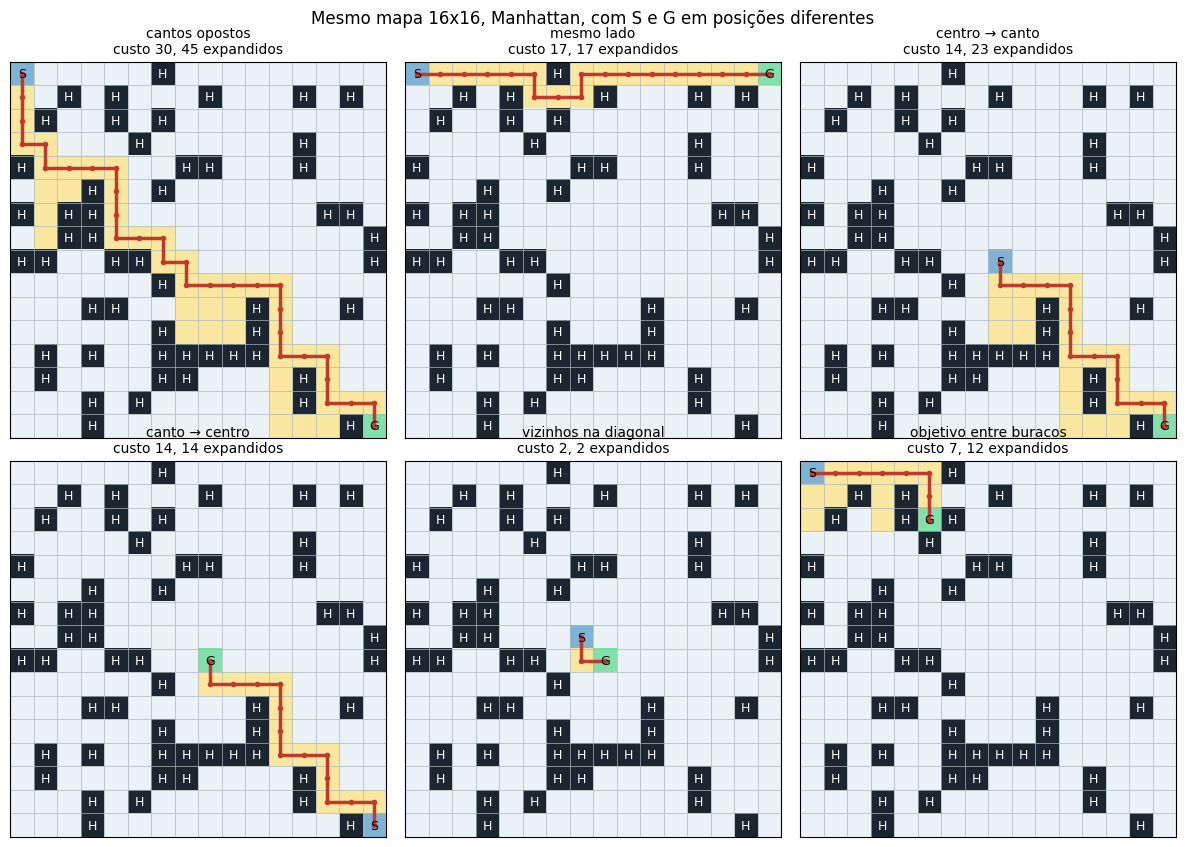

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(12, 8.6))
for ax, (nome, (s, g)) in zip(axes.flat, POSICOES.items()):
    mapa = posicionar(base16, s, g)
    desenhar(mapa, a_star(mapa, heuristica_fn=manhattan), ax=ax)
    ax.set_title(f"{nome}\n{ax.get_title()}", fontsize=10)
plt.suptitle("Mesmo mapa 16x16, Manhattan, com S e G em posições diferentes")
plt.tight_layout()
plt.savefig(FIGURAS / "cenario_posicoes.png", dpi=150, bbox_inches="tight")
plt.show()

### 3. Buracos

#### 3a. Densidade

Mapas 32x32 com S em (0,0) e G em (31,31), em que cada célula vira buraco com probabilidade $1 - p$. Aqui os mapas **não** são filtrados, então nem todos têm caminho. São 50 mapas por valor de $p$. A coluna `custo / h(S)` compara o caminho real com a Manhattan inicial, que é 62.

In [14]:
P_LIVRE = [1.0, 0.9, 0.8, 0.7, 0.65, 0.6]
N_MAPAS_DENS = 50

linhas = []
for p in P_LIVRE:
    for k in range(N_MAPAS_DENS):
        mapa = montar_mapa(32, p_livre=p, semente=SEMENTE * 1000 + k)
        for linha in rodar(mapa, {"nula (Dijkstra)": heuristica_nula, "manhattan": manhattan}):
            linhas.append({"p": p, "mapa": k, **linha})

df_dens = pd.DataFrame(linhas)
com_caminho = df_dens[df_dens.encontrou]
so_manh = com_caminho[com_caminho.heuristica == "manhattan"].groupby("p")
so_nula = com_caminho[com_caminho.heuristica == "nula (Dijkstra)"].groupby("p")
tab_dens = pd.DataFrame({
    "% com caminho": df_dens[df_dens.heuristica == "manhattan"].groupby("p").encontrou.mean() * 100,
    "custo médio": so_manh.custo.mean(),
    "custo / h(S)": so_manh.custo.mean() / 62,
    "expandidos nula": so_nula.expandidos.mean(),
    "expandidos manhattan": so_manh.expandidos.mean(),
}).sort_index(ascending=False).round(2)
tab_dens["economia da manhattan (%)"] = (100 * (1 - tab_dens["expandidos manhattan"] / tab_dens["expandidos nula"])).round(1)
tab_dens

,% com caminho,custo médio,custo / h(S),expandidos nula,expandidos manhattan,economia da manhattan (%)
p,,,,,,
1.00,100.0,62.00,1.00,1023.00,62.00,93.9
0.90,100.0,62.00,1.00,919.24,103.06,88.8
0.80,86.0,62.05,1.00,814.42,131.67,83.8
0.70,40.0,63.10,1.02,691.70,181.20,73.8
0.65,26.0,66.31,1.07,587.38,234.77,60.0
0.60,8.0,80.00,1.29,412.25,267.50,35.1


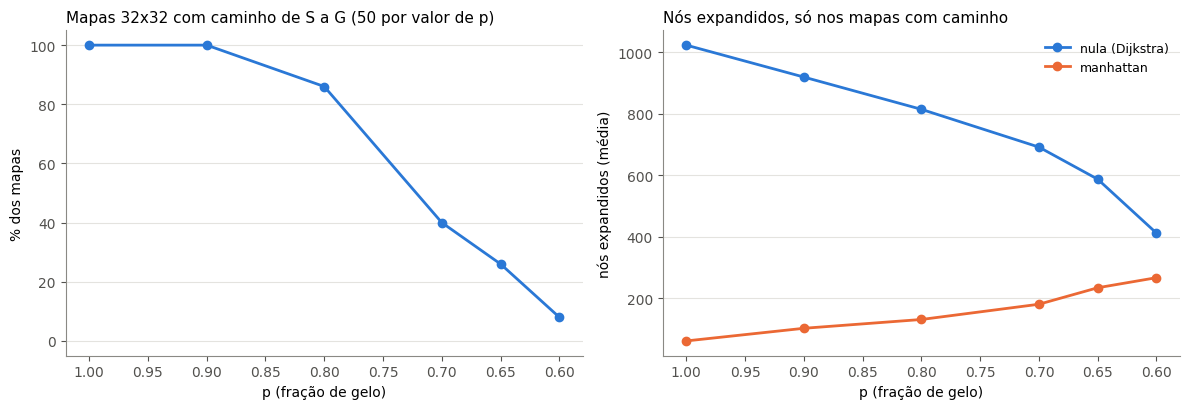

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ps = tab_dens.index.to_numpy()
axes[0].plot(ps, tab_dens["% com caminho"], color="#2a78d6", linewidth=2, marker="o", markersize=6)
estilo(axes[0], "Mapas 32x32 com caminho de S a G (50 por valor de p)", "p (fração de gelo)", "% dos mapas")
axes[0].set_ylim(-5, 105)
d = com_caminho.groupby(["heuristica", "p"], sort=False).expandidos.mean().reset_index().sort_values("p")
linhas_por_heuristica(axes[1], d, "p", "expandidos", ["nula (Dijkstra)", "manhattan"])
estilo(axes[1], "Nós expandidos, só nos mapas com caminho", "p (fração de gelo)", "nós expandidos (média)")
axes[1].legend(frameon=False, fontsize=9)
for ax in axes:
    ax.invert_xaxis()
plt.tight_layout()
plt.savefig(FIGURAS / "cenario_densidade.png", dpi=150, bbox_inches="tight")
plt.show()

#### 3b. Padrões montados à mão

Mapas aleatórios escondem casos em que a heurística é enganada. Os padrões abaixo isolam esses casos:

- **parede com passagem alinhada**: a passagem fica na linha de S e G, então a Manhattan é exata;
- **parede com passagem na ponta**: a passagem fica no canto, e o caminho real é quase o dobro da estimativa;
- **armadilha em "U"**: um U aberto para o S fica entre S e G, e a Manhattan puxa a busca para dentro dele;
- **labirinto perfeito** (31x31): só existe um caminho, cheio de voltas;
- **labirinto com ciclos**: o mesmo labirinto com 10% das paredes internas removidas.

In [16]:
PADROES = {
    "parede, passagem alinhada": mapa_parede(16, 8),
    "parede, passagem na ponta": mapa_parede(16, 0),
    "armadilha em U": mapa_armadilha_u(16),
    "labirinto perfeito": mapa_labirinto(31, semente=SEMENTE),
    "labirinto com ciclos": mapa_labirinto(31, semente=SEMENTE, abrir=0.10),
}

linhas = []
for nome, mapa in PADROES.items():
    s, g = encontrar(mapa, "S"), encontrar(mapa, "G")
    for linha in rodar(mapa, HEURISTICAS):
        linhas.append({"padrão": nome, "h(S)": manhattan(s, g), "alcançáveis": alcancaveis(mapa), **linha})

df_pad = pd.DataFrame(linhas)
tab_pad = df_pad.pivot_table(index=["padrão", "h(S)", "custo", "alcançáveis"], columns="heuristica",
                             values="expandidos", sort=False).reset_index()
tab_pad.columns.name = None
tab_pad

,padrão,h(S),custo,alcançáveis,nula (Dijkstra),manhattan,euclidiana
0,"parede, passagem alinhada",15.0,15.0,241,170.0,15.0,15.0
1,"parede, passagem na ponta",15.0,31.0,241,212.0,136.0,178.0
2,armadilha em U,14.0,24.0,231,230.0,107.0,181.0
3,labirinto perfeito,60.0,264.0,511,346.0,315.0,316.0
4,labirinto com ciclos,60.0,84.0,533,514.0,341.0,434.0


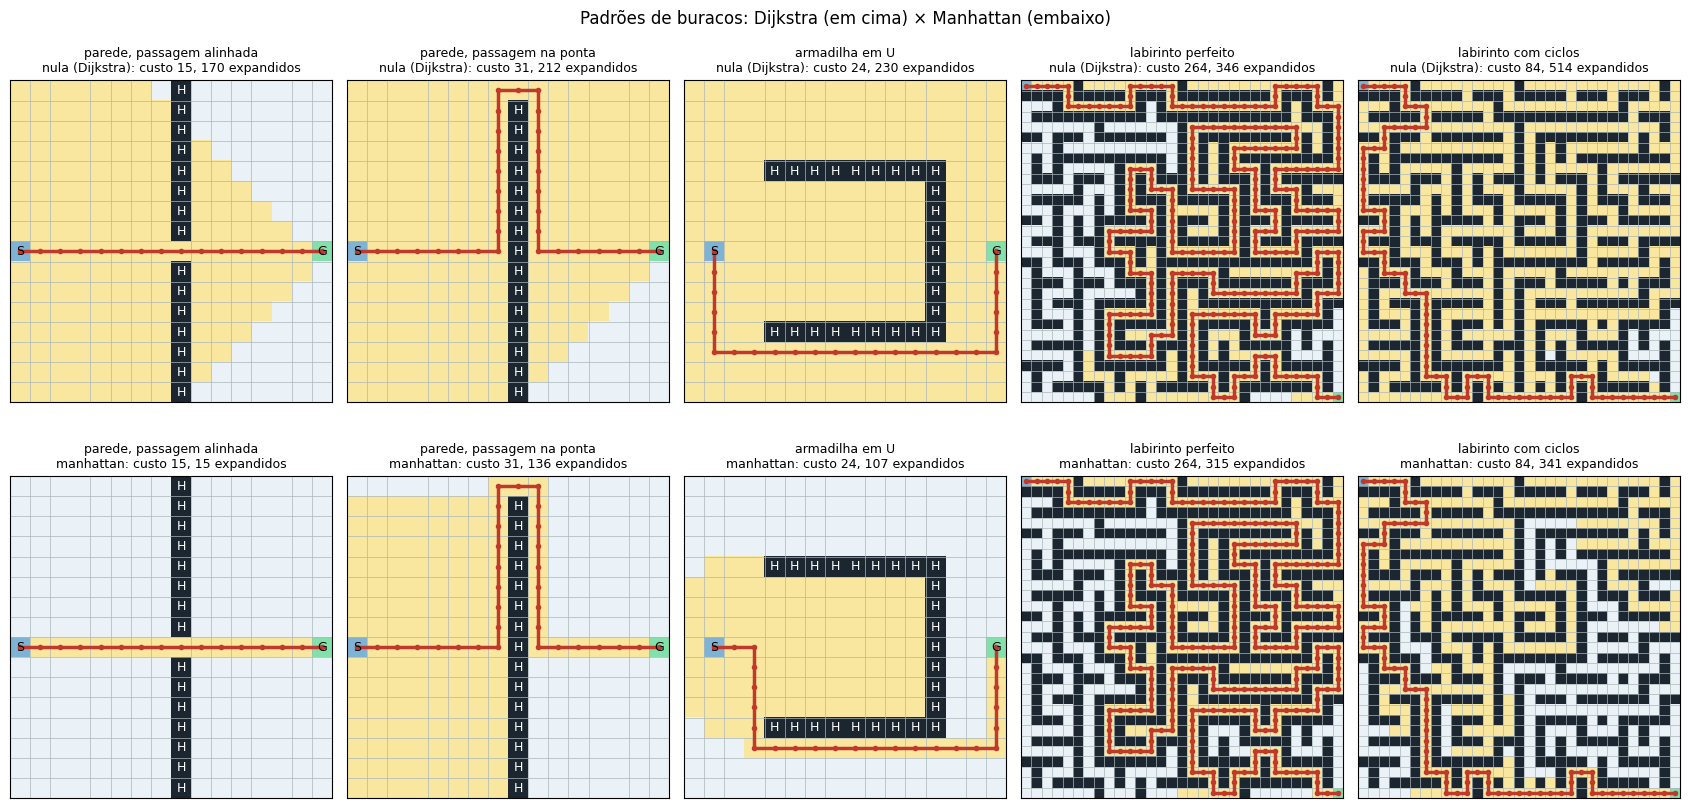

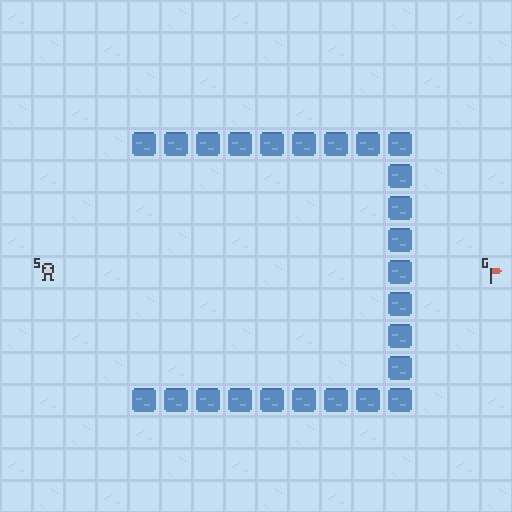

In [17]:
fig, axes = plt.subplots(2, len(PADROES), figsize=(17, 8.6))
for col, (nome, mapa) in enumerate(PADROES.items()):
    for lin, (nome_h, h) in enumerate([("nula (Dijkstra)", heuristica_nula), ("manhattan", manhattan)]):
        ax = axes[lin, col]
        desenhar(mapa, a_star(mapa, heuristica_fn=h), ax=ax)
        ax.set_title(f"{nome}\n{nome_h}: {ax.get_title()}", fontsize=9)
plt.suptitle("Padrões de buracos: Dijkstra (em cima) × Manhattan (embaixo)")
plt.tight_layout(h_pad=2.5)
plt.savefig(FIGURAS / "cenario_padroes.png", dpi=150, bbox_inches="tight")
plt.show()

gerar_gif(PADROES["armadilha em U"], a_star(PADROES["armadilha em U"]).acoes,
          FIGURAS / "cenario_armadilha_u.gif", duracao_ms=200)
display(Image(filename=FIGURAS / "cenario_armadilha_u.gif"))

### 4. Mapas sem solução

Quando não há caminho, o A* só para depois de esvaziar a fronteira. Os casos testados são o G cercado por um anel de buracos (16x16) e três dos mapas de densidade $p = 0.6$ que ficaram sem caminho.

In [18]:
casos = {"objetivo cercado (16x16)": mapa_objetivo_isolado(16)}
sem_caminho_06 = [k for k in range(N_MAPAS_DENS)
                  if not existe_caminho(montar_mapa(32, p_livre=0.6, semente=SEMENTE * 1000 + k))]
for k in sem_caminho_06[:3]:
    casos[f"p = 0.6, mapa {k} (32x32)"] = montar_mapa(32, p_livre=0.6, semente=SEMENTE * 1000 + k)

linhas = []
for nome, mapa in casos.items():
    for linha in rodar(mapa, {**HEURISTICAS, "manhattan ×2": HEURISTICAS_PONDERADAS["manhattan ×2"]}):
        linhas.append({"mapa": nome, "alcançáveis a partir de S": alcancaveis(mapa), **linha})

df_sem = pd.DataFrame(linhas)
tab_sem = df_sem.pivot_table(index=["mapa", "alcançáveis a partir de S"], columns="heuristica",
                             values="expandidos", sort=False).reset_index()
tab_sem.columns.name = None
tab_sem

,mapa,alcançáveis a partir de S,nula (Dijkstra),manhattan,euclidiana,manhattan ×2
0,objetivo cercado (16x16),247,247.0,247.0,247.0,623.0
1,"p = 0.6, mapa 0 (32x32)",29,29.0,29.0,29.0,29.0
2,"p = 0.6, mapa 1 (32x32)",8,8.0,8.0,8.0,8.0
3,"p = 0.6, mapa 2 (32x32)",493,493.0,493.0,493.0,598.0


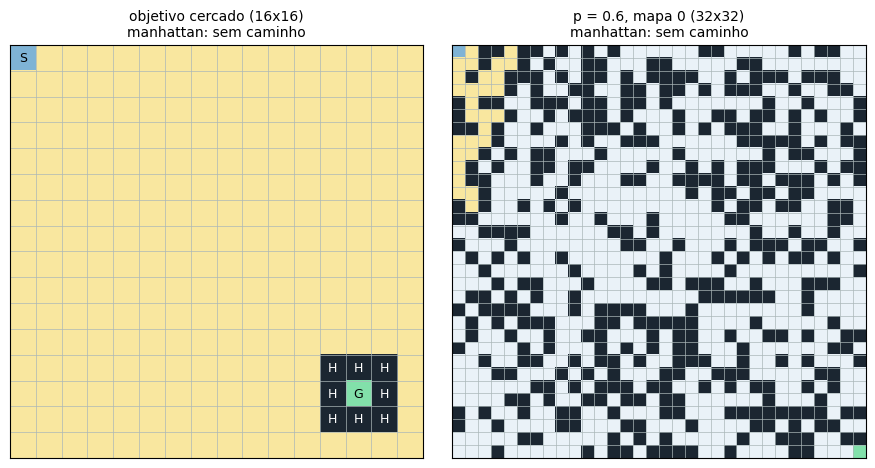

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4.6))
for ax, (nome, mapa) in zip(axes, list(casos.items())[:2]):
    desenhar(mapa, a_star(mapa, heuristica_fn=manhattan), ax=ax)
    ax.set_title(f"{nome}\nmanhattan: {ax.get_title()}", fontsize=10)
plt.tight_layout()
plt.savefig(FIGURAS / "cenario_sem_caminho.png", dpi=150, bbox_inches="tight")
plt.show()

### 5. Heurísticas

As heurísticas são comparadas em 50 mapas 32x32 do `generate_random_map` para cada densidade ($p = 0.8$ e $p = 0.7$) e nos padrões da seção 3b. A Manhattan com peso $w$ multiplica a estimativa por $w$. Para $w > 1$ ela pode superestimar o custo real, então deixa de ser admissível, e o A* perde a garantia de achar o caminho de menor custo. A coluna `% subótimos` conta em quantos mapas o custo ficou acima do de Dijkstra, e `excesso máx. (%)` mostra o pior caso.

In [20]:
TODAS = {**HEURISTICAS, **HEURISTICAS_PONDERADAS}

linhas = []
for p in (0.8, 0.7):
    for k in range(50):
        mapa = generate_random_map(size=32, p=p, seed=SEMENTE + k)
        for linha in rodar(mapa, TODAS):
            linhas.append({"conjunto": f"aleatórios p = {p}", "mapa": k, **linha})
for nome, mapa in PADROES.items():
    for linha in rodar(mapa, TODAS):
        linhas.append({"conjunto": "padrões (3b)", "mapa": nome, **linha})

df_h = pd.DataFrame(linhas)
df_h["subotimo"] = df_h["excesso_%"] > 1e-9
tab_h = (df_h.groupby(["conjunto", "heuristica"], sort=False)
         .agg(expandidos=("expandidos", "mean"), max_fronteira=("max_fronteira", "mean"),
              **{"% subótimos": ("subotimo", lambda s: 100 * s.mean()),
                 "excesso médio (%)": ("excesso_%", "mean"),
                 "excesso máx. (%)": ("excesso_%", "max")})
         .round(1))
tab_h

expandidos  max_fronteira  % subótimos  \
conjunto           heuristica                                                
aleatórios p = 0.8 nula (Dijkstra)       814.8           32.4          0.0   
                   manhattan             133.4           90.4          0.0   
                   euclidiana            695.3           52.4          0.0   
                   manhattan ×1.5        102.2           66.5         90.0   
                   manhattan ×2           97.7           64.4         98.0   
                   manhattan ×5           93.5           63.9        100.0   
aleatórios p = 0.7 nula (Dijkstra)       683.3           27.5          0.0   
                   manhattan             192.0           75.7          0.0   
                   euclidiana            500.3           42.4          0.0   
                   manhattan ×1.5        122.0           56.8         74.0   
                   manhattan ×2          113.0           55.4         88.0   
                   manhattan ×5          113.2           55.6         98.0   
padrões (3b)       nula (Dijkstra)       294.4           12.6          0.0   
                   manhattan             182.8           20.8          0.0   
                   euclidiana            224.8           20.6          0.0   
                   manhattan ×1.5        177.2           22.0          0.0   
                   manhattan ×2          177.0           22.2         20.0   
                   manhattan ×5          157.2           22.6         20.0   

                                    excesso médio (%)  excesso máx. (%)  
conjunto           heuristica                                            
aleatórios p = 0.8 nula (Dijkstra)                0.0               0.0  
                   manhattan                      0.0               0.0  
                   euclidiana                     0.0               0.0  
                   manhattan ×1.5                 5.6              12.9  
                   manhattan ×2                   9.5              19.4  
                   manhattan ×5                  15.1              38.7  
aleatórios p = 0.7 nula (Dijkstra)                0.0               0.0  
                   manhattan                      0.0               0.0  
                   euclidiana                     0.0               0.0  
                   manhattan ×1.5                 4.2              16.1  
                   manhattan ×2                   8.3              28.1  
                   manhattan ×5                  15.2              53.1  
padrões (3b)       nula (Dijkstra)                0.0               0.0  
                   manhattan                      0.0               0.0  
                   euclidiana                     0.0               0.0  
                   manhattan ×1.5                 0.0               0.0  
                   manhattan ×2                   2.9              14.3  
                   manhattan ×5                   5.7              28.6

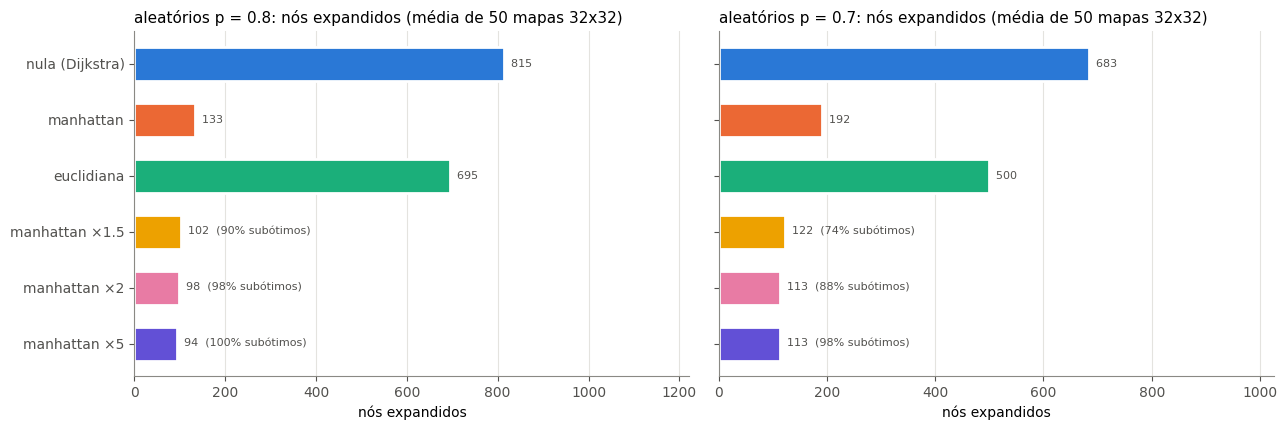

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
for ax, conjunto in zip(axes, ["aleatórios p = 0.8", "aleatórios p = 0.7"]):
    d = tab_h.loc[conjunto].reset_index()
    y = list(range(len(d)))
    ax.barh(y, d.expandidos, color=[CORES[n] for n in d.heuristica], height=0.6,
            edgecolor="white", linewidth=2)
    for yi, (v, sub) in enumerate(zip(d.expandidos, d["% subótimos"])):
        rotulo = f"{v:.0f}" + (f"  ({sub:.0f}% subótimos)" if sub > 0 else "")
        ax.text(v, yi, "  " + rotulo, va="center", fontsize=8, color="#52514e")
    ax.set_yticks(y, d.heuristica)
    estilo(ax, f"{conjunto}: nós expandidos (média de 50 mapas 32x32)", "nós expandidos", "")
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", color="#e4e3df", linewidth=0.8)
    ax.set_xlim(0, d.expandidos.max() * 1.5)
axes[0].invert_yaxis()
plt.tight_layout()
plt.savefig(FIGURAS / "cenario_heuristicas.png", dpi=150, bbox_inches="tight")
plt.show()